In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, Dense, Dropout
from sklearn.metrics import classification_report

In [2]:
# Load IMDB dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=10000)

In [3]:
print("Training size:", len(X_train))
print("Testing size:", len(X_test))

Training size: 25000
Testing size: 25000


In [4]:
print("First review:", X_train[0])
print("Sentiment:", y_train[0])
print("Review length:", len(X_train[0]))

First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]
Sentiment: 1
Review length: 218


In [5]:
max_length = 200

X_train_pad = pad_sequences(
    X_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [6]:
# RNN model

rnn_model = Sequential()
rnn_model.add(Input(shape=(200,)))
rnn_model.add(Embedding(
        input_dim=10000,
        output_dim=64,
        input_length=200)),

rnn_model.add(SimpleRNN(64)),

rnn_model.add(Dropout(0.3)),

rnn_model.add(Dense(1, activation='sigmoid'))

rnn_model.summary()

c:\Users\USER2\Desktop\python\DL\vs\.myenv\Lib\site-packages\keras\src\layers\core\embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,321 (2.47 MB)

 Trainable params: 648,321 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
rnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [8]:
history_rnn = rnn_model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.5045 - loss: 0.6990 - val_accuracy: 0.5116 - val_loss: 0.6926
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - accuracy: 0.5883 - loss: 0.6647 - val_accuracy: 0.5146 - val_loss: 0.6996
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.6771 - loss: 0.5669 - val_accuracy: 0.5136 - val_loss: 0.7635
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.7258 - loss: 0.4639 - val_accuracy: 0.5046 - val_loss: 0.8602
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.7574 - loss: 0.3993 - val_accuracy: 0.5114 - val_loss: 0.8801


In [9]:
rnn_loss, rnn_accuracy = rnn_model.evaluate(X_test_pad, y_test)

print("RNN Test Accuracy:", rnn_accuracy)
print("RNN Test Loss:", rnn_loss)

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5137 - loss: 0.8807
RNN Test Accuracy: 0.5137199759483337
RNN Test Loss: 0.8807361125946045


In [10]:
y_pred_prob_rnn = rnn_model.predict(X_test_pad)

y_pred_rnn = (y_pred_prob_rnn > 0.5).astype(int)

782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step


In [13]:
print(classification_report( y_test, y_pred_rnn))

              precision    recall  f1-score   support

           0       0.52      0.29      0.37     12500
           1       0.51      0.74      0.60     12500

    accuracy                           0.51     25000
   macro avg       0.52      0.51      0.49     25000
weighted avg       0.52      0.51      0.49     25000



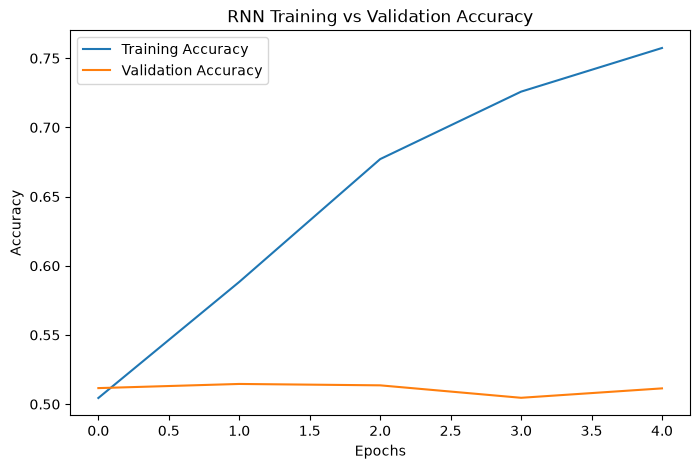

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history_rnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_rnn.history['val_accuracy'], label='Validation Accuracy')

plt.title('RNN Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

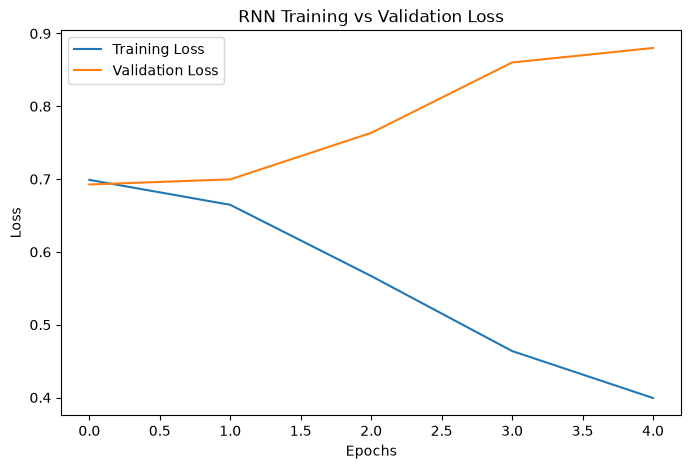

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history_rnn.history['loss'], label='Training Loss')
plt.plot(history_rnn.history['val_loss'], label='Validation Loss')

plt.title('RNN Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.show()

In [16]:
lstm_model = Sequential()

lstm_model.add(Input(shape=(200,)))

lstm_model.add(Embedding(
    input_dim=10000,
    output_dim=64
))

lstm_model.add(LSTM(64))
lstm_model.add(Dropout(0.5))
lstm_model.add(Dense(1, activation='sigmoid'))


lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [18]:
history_lstm = lstm_model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5


625/625 ━━━━━━━━━━━━━━━━━━━━ 34s 51ms/step - accuracy: 0.5147 - loss: 0.6932 - val_accuracy: 0.5180 - val_loss: 0.6916
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 34s 55ms/step - accuracy: 0.5724 - loss: 0.6718 - val_accuracy: 0.6018 - val_loss: 0.6488
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 33s 53ms/step - accuracy: 0.6372 - loss: 0.6212 - val_accuracy: 0.5766 - val_loss: 0.6556
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 32s 51ms/step - accuracy: 0.6504 - loss: 0.6163 - val_accuracy: 0.6736 - val_loss: 0.6198
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.6040 - loss: 0.6490 - val_accuracy: 0.5400 - val_loss: 0.6799


In [19]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(X_test_pad, y_test)

print("LSTM Test Accuracy:", lstm_accuracy)
print("LSTM Test Loss:", lstm_loss)

782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - accuracy: 0.5430 - loss: 0.6800
LSTM Test Accuracy: 0.5429999828338623
LSTM Test Loss: 0.6800281405448914


In [20]:
y_pred_prob_lstm = lstm_model.predict(X_test_pad)

y_pred_lstm = (y_pred_prob_lstm > 0.5).astype(int).flatten()

782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step


In [21]:

print(classification_report(y_test, y_pred_lstm))

              precision    recall  f1-score   support

           0       0.61      0.24      0.34     12500
           1       0.53      0.85      0.65     12500

    accuracy                           0.54     25000
   macro avg       0.57      0.54      0.50     25000
weighted avg       0.57      0.54      0.50     25000



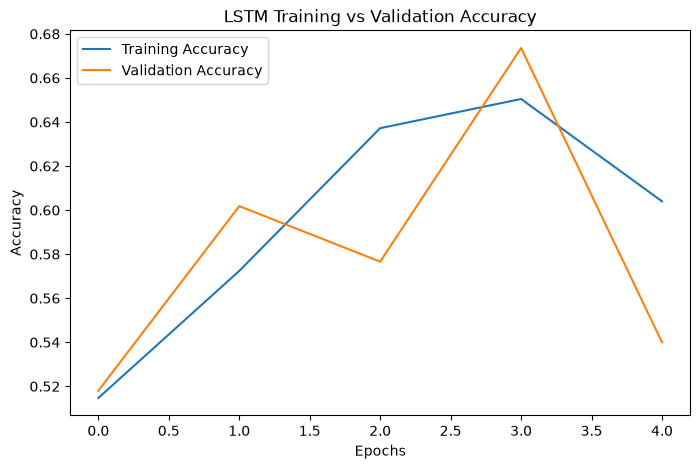

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history_lstm.history['accuracy'], label='Training Accuracy')
plt.plot(history_lstm.history['val_accuracy'], label='Validation Accuracy')

plt.title('LSTM Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

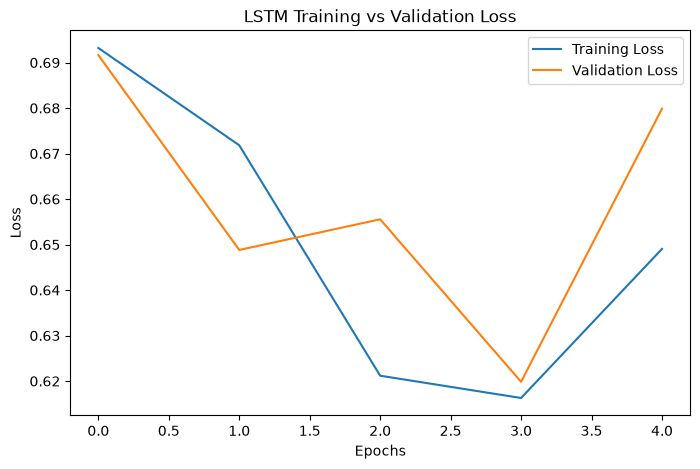

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(history_lstm.history['loss'], label='Training Loss')
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')

plt.title('LSTM Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.show()

In [24]:
model_comparison = pd.DataFrame({
    'Model': ['Simple RNN', 'LSTM'],
    'Accuracy': [rnn_accuracy, lstm_accuracy],
    'Loss': [rnn_loss, lstm_loss]
})

print(model_comparison)

        Model  Accuracy      Loss
0  Simple RNN   0.51372  0.880736
1        LSTM   0.54300  0.680028


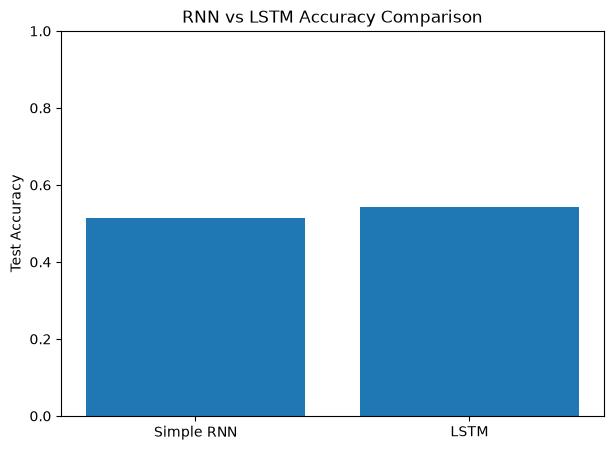

In [25]:
plt.figure(figsize=(7, 5))

plt.bar(model_comparison['Model'], model_comparison['Accuracy'])

plt.title('RNN vs LSTM Accuracy Comparison')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1)

plt.show()